# Measuring

`pemlab-instruments` controls the instruments with pyvisa and writes CSV files. It does not need
pemlab; the evaluation of the files happens there (`lab.edit_csv(...)`).

This notebook runs **without hardware**: `Bench` simulates an RC high-pass (cutoff 700 Hz) behind
a function generator and two multimeters. In the lab you open the real instruments instead
(see the first cell), everything below stays the same.

In [1]:
# In the lab:
#   import pyvisa
#   rm = pyvisa.ResourceManager()
#   awg   = AFG1022(rm.open_resource("USB0::0x0699::0x0353::1511374::INSTR"))
#   dmm_e = rm.open_resource("TCPIP::141.48.16.191::INSTR")    # measures U_e
#   dmm_a = rm.open_resource("TCPIP::...")                     # measures U_a
# find_instruments() prints these lines for everything that is connected.
import re
import numpy as np

class Bench:
    "The simulated circuit: remembers the frequency of the generator."
    def __init__(self):
        self.f = 1000.0
        self.rng = np.random.default_rng(1)

class FakeAFG:
    def __init__(self, bench):
        self.bench, self.written = bench, []
    def write(self, command):
        self.written.append(command)
        found = re.match(r"SOURce1:FREQuency:FIXed (\S+)Hz", command)
        if found:
            self.bench.f = float(found.group(1))

class FakeDMM:
    def __init__(self, bench, kind):
        self.bench, self.kind = bench, kind
    def write(self, command):
        pass
    def query(self, command):
        f_over_fg = self.bench.f / 700
        gain = 1.0 if self.kind == "in" else f_over_fg / np.sqrt(1 + f_over_fg**2)
        return str(0.354 * gain * (1 + 0.004 * self.bench.rng.standard_normal()))

bench = Bench()
fake_awg, dmm_e, dmm_a = FakeAFG(bench), FakeDMM(bench, "in"), FakeDMM(bench, "out")

## Generator and multimeters

In [2]:
from pemlab_instruments import AFG1022, measure_repeated, measure_voltage

awg = AFG1022(fake_awg)                              # lab: AFG1022(rm.open_resource(address))
awg.settings("sine", frequency=1000, amplitude=1)    # shape, frequency [Hz], amplitude [Vpp]
awg.on()
awg.set_frequency(700)
fake_awg.written[-3:]                                # the SCPI commands that were sent

['SOURce1:FREQuency:FIXed 1000Hz',
 'OUTPut1:STATe ON',
 'SOURce1:FREQuency:FIXed 700Hz']

In [3]:
measure_voltage(dmm_a, ac=True)                                        # one value in V
measure_repeated(lambda: measure_voltage(dmm_a, ac=True), n=5)         # five values, e.g. for a mean

[0.25113845655335265,
 0.2506466550250496,
 0.2490109971574034,
 0.2512223000541974,
 0.2507627389737258]

## A sweep in a `with` block, with live plot and csv

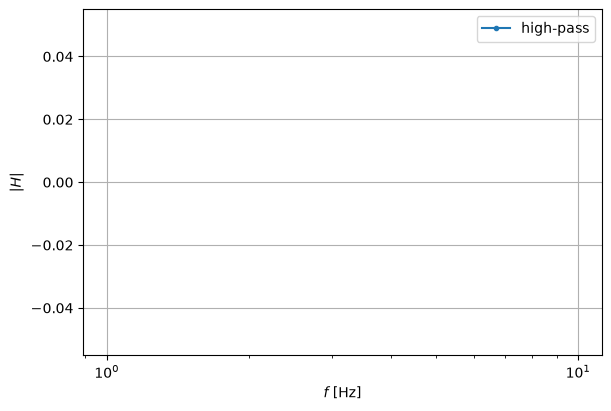

In [4]:
from pemlab_instruments import LivePlot, LiveStyle, LogSweep

columns = ["f [Hz]", "U_e [V]", "U_a [V]"]

with LogSweep(50, 5000, 30, columns=columns, save="data/highpass.csv") as sweep:
    plot = LivePlot(                                    # redrawn after every sweep.add(...)
        sweep, x="f [Hz]", y=lambda row: row["U_a [V]"] / row["U_e [V]"],
        style=LiveStyle(xscale="log", xlabel="$f$ [Hz]", ylabel="$|H|$", label="high-pass"),
    )
    for f in sweep:                                     # you write the loop
        awg.set_frequency(f)                            # 1. set
        sweep.wait(0.01)                                # 2. settle (lab: 0.3 s or more)
        sweep.add(measure_voltage(dmm_e, ac=True),      # 3. measure and store the row
                  measure_voltage(dmm_a, ac=True))
# in a script: plot.show() keeps the window open after the measurement

In [5]:
sweep.log.to_arrays()["f [Hz]"][:3]                     # the rows so far, as arrays
print(open("data/highpass.csv").read()[:150])           # the csv was written row by row

f [Hz],U_e [V],U_a [V]
50,0.353239674219,0.0252800822738
58.6051148767,0.354516234513,0.0295688655083
68.6911897942,0.354040245894,0.034647662079
80.5


## Ctrl+C, other sweeps, own reactions

In [6]:
# Ctrl+C ends the block cleanly, the rows so far stay in the csv; here the same exception after 10 rows
with LogSweep(50, 5000, 30, columns=columns, save="data/interrupted.csv") as sweep:
    for k, f in enumerate(sweep):
        awg.set_frequency(f)
        sweep.add(measure_voltage(dmm_e, ac=True), measure_voltage(dmm_a, ac=True))
        if k == 9:
            raise KeyboardInterrupt
print(sweep.interrupted, len(sweep.log), "rows kept")

Messung abgebrochen nach 10 Zeilen.
True 10 rows kept


In [7]:
from pemlab_instruments import LinSweep, Timed

# linear steps, own reaction after every row (printing, a second plot, a check, ...)
with LinSweep(100, 1000, 4, columns=columns) as sweep:
    sweep.on_row(lambda s: print(f"{len(s.log)} rows, last U_a = {s.log.rows[-1][2]:.3f} V"))
    for f in sweep:
        awg.set_frequency(f)
        sweep.add(measure_voltage(dmm_e, ac=True), measure_voltage(dmm_a, ac=True))

1 rows, last U_a = 0.050 V
2 rows, last U_a = 0.176 V
3 rows, last U_a = 0.251 V
4 rows, last U_a = 0.290 V


In [8]:
# over time: the first column is the real time since the start (without duration: until Ctrl+C)
with Timed(0.05, columns=["t [s]", "U_a [V]"], duration=0.3) as run:
    for t in run:
        run.add(measure_voltage(dmm_a, ac=True))
run.log.to_arrays()["t [s]"].round(2)

array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 ])

## Without a sweep object

In [9]:
from pemlab_instruments import MeasurementLog, measure_series

# the simple form: for every value set, wait, measure
log = measure_series(
    [100, 700, 3000], awg.set_frequency, lambda: measure_voltage(dmm_a, ac=True),
    ["f [Hz]", "U_a [V]"], settle=0, verbose=False,
)
log.save("data/series.csv")                           # a MeasurementLog saves itself as csv
log

MeasurementLog(['f [Hz]', 'U_a [V]'], 3 rows)

In [10]:
from pemlab_instruments import edge_times, find_peak

# a recorded signal (oscilloscope: t, u = scope.read_waveform()) and its evaluation
t = np.linspace(0, 1e-3, 2000)
u = np.sin(2 * np.pi * 3000 * t)
print(edge_times(t, u, 0.0)[:2], find_peak(t, u))

[0.00033333333388246936, 0.0006666666661175307] (0.00041666666696699937, 1.0000000000752927)


## Next: the evaluation

The CSV files are ordinary measurement files. With the package `pemlab` (see its documentation):

```python
lab = Project("build")
highpass = lab.edit_csv("data/highpass.csv")
highpass.add_column("H", lambda U_a, U_e: U_a / U_e)
```